# Bregman proximal point minimization

Let $f$ and $h$ be closed, proper, convex functions on a real finite-dimensional Euclidean space, with the differentiability stipulated in the input; $h$ is a differentiable Bregman kernel. Let $x_\star$ minimize $f$, $\alpha>0$, $R\ge0$, and $N\ge1$ be an integer. All iterates and evaluations are well-defined.

$$D_h(u,v)=h(u)-h(v)-\langle\nabla h(v),u-v\rangle,$$
$$x_{k+1}\in\mathop{\rm argmin}_x\{\alpha f(x)+D_h(x,x_k)\},\quad k=0,\ldots,N-1.$$

The model uses the exact optimality relation
$$\nabla h(x_{k+1})=\nabla h(x_k)-\alpha\nabla f(x_{k+1}).$$
The initial condition is $D_h(x_\star,x_0)\le R$ (not $R^2$), and the metric is $f(x_N)-f(x_\star)$. Convex interpolation gives an upper-bound PEP relaxation for the supplied differentiable class; no extra smoothness or strong convexity is imposed.

## Proof Statement

### Theorem
Under the assumptions stated above, let $\alpha>0$, $R\ge0$, and integer $N\ge1$, and let the exact Bregman proximal iterates satisfy $D_h(x_{\star},x_{0})\le R$. Define, for $0\le k\le N$,
$$V_{k}=\frac{k}{N}\bigl(f(x_{k})-f(x_{\star})\bigr)+\frac{D_h(x_{\star},x_{k})-D_h(x_{\star},x_{0})}{\alpha N}.$$
Then $V_{0}=0$ and $V_{k}$ is nonincreasing. Consequently,
$$0\le f(x_{N})-f(x_{\star})\le\frac{R}{\alpha N}.$$
Equivalently, the unshifted potential is $\Phi_{k}=V_{k}+D_h(x_{\star},x_{0})/(\alpha N)$. The result includes $N=1$ and $R=0$.

### Proof outline
For a convex function $q$, define the nonpositive residual
$$C^q_{u,v}=q(v)-q(u)+\langle\nabla q(v),u-v\rangle\le0.$$
Use the potential
$$V_{k}=\frac{k}{N}(f(x_{k})-f(x_{\star}))+\frac{D_h(x_{\star},x_{k})-D_h(x_{\star},x_{0})}{\alpha N}.$$
At the base, $V_{0}=0$. Exact proximal optimality gives $\nabla h(x_j)=\nabla h(x_{j-1})-\alpha\nabla f(x_j)$. Expanding the Bregman terms yields, for every $1\le j\le N$,
$$V_j-V_{j-1}=\frac1N C^f_{x_{\star},x_j}+\frac{j-1}{N}C^f_{x_{j-1},x_j}
+\frac{j}{\alpha N}C^h_{x_j,x_{j-1}}+\frac{j-1}{\alpha N}C^h_{x_{j-1},x_j}\le0.$$
Every coefficient is nonnegative; the terms with $j-1$ vanish at the first step. No additional square or matrix residual appears in this exact local identity. Hence $V_N\le0$.

Finally,
$$f(x_N)-f(x_{\star})-\frac{R}{\alpha N}=V_N+\frac{D_h(x_{\star},x_0)-R}{\alpha N}+\frac{C^h_{x_{\star},x_N}}{\alpha N}\le0.$$
The initial assumption controls the middle term and $C^h_{x_{\star},x_N}=-D_h(x_{\star},x_N)\le0$ by convexity. Thus the bound uses radius $R$, not $R^2$. The executable symbolic checks below verify these identities with symbolic indices and parameters in all scalar components.

In [1]:
from pathlib import Path
import sys
notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir), str(notebook_dir / "supplementary")]


In [2]:
import json
from numbers import Number
from typing import cast
import pepflow as pf
import matplotlib.pyplot as plt

## Function and parameter definitions

In [3]:
alpha = pf.Parameter("alpha")
R = pf.Parameter("R")
f = pf.ConvexFunction(is_basis=True, tags=["f"])
h = pf.ConvexFunction(is_basis=True, tags=["h"])



## Algorithm and PEP setup

In [4]:
def make_ctx_bppm(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    f.set_stationary_point("x_star")
    f(x)
    for k in range(int(N)):
        x = f.bregman_prox(x, cast(Number, alpha), h, tag=f"x_{k + 1}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_bppm(f"ctx_{N}", N)
    x0, xs = ctx["x_0"], ctx["x_star"]
    divergence = h(xs) - h(x0) - h.grad(x0) * (xs - x0)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(divergence.le(R, name="initial_condition"))
    pb.set_performance_metric(f(ctx[f"x_{N}"]) - f(xs))
    return ctx, pb, f


ctx_b1, pb_b1, obj_b1 = get_pep_setup(4, {"alpha": 1, "R": 1})
print("Built four exact Bregman proximal steps.")

Built four exact Bregman proximal steps.


## Numerical evidence
The saved sweep uses CLARABEL defaults, with alpha = R = 1, and one numerical thread. Each solve includes convex interpolation for both f and h.

N=1: PEP=1.0000000006; conjecture=1.0000000000; status=optimal
N=2: PEP=0.4999999958; conjecture=0.5000000000; status=optimal
N=3: PEP=0.3333333333; conjecture=0.3333333333; status=optimal
N=4: PEP=0.2499999995; conjecture=0.2500000000; status=optimal
N=5: PEP=0.1999999999; conjecture=0.2000000000; status=optimal
N=6: PEP=0.1666666661; conjecture=0.1666666667; status=optimal
N=7: PEP=0.1428571412; conjecture=0.1428571429; status=optimal
Maximum absolute discrepancy: 4.241e-09 (tolerance 1e-5)


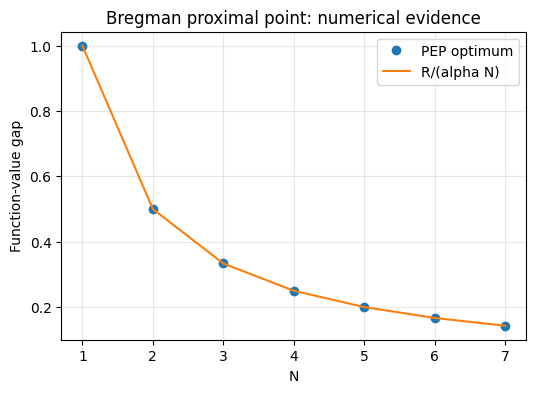

In [5]:
sweep = json.loads((notebook_dir / "state/bppm_b1.json").read_text())["sweep_results"]
for row in sweep:
    print(f"N={row['N']}: PEP={row['opt_value']:.10f}; conjecture={row['conjecture']:.10f}; status={row['solver_attempts'][-1]['status']}")
error = max(row["absolute_error"] for row in sweep)
assert error <= 1e-5
print(f"Maximum absolute discrepancy: {error:.3e} (tolerance 1e-5)")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([r["N"] for r in sweep], [r["opt_value"] for r in sweep], "o", label="PEP optimum")
ax.plot([r["N"] for r in sweep], [r["conjecture"] for r in sweep], "-", label="R/(alpha N)")
ax.set(xlabel="N", ylabel="Function-value gap", title="Bregman proximal point: numerical evidence")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

The observed values match $R/(\alpha N)$ at the normalized parameters. This is numerical evidence, not an arbitrary-horizon proof.

## Dense and relaxed proof solves
The complete dense solve at $N=4$ contains both convex interpolation families. Its near-zero Gram dual suggests a certificate using only scalar interpolation inequalities. We keep $f$ inequalities from the optimum to every iterate and from each preceding iterate to its successor, both directions of adjacent $h$ inequalities, and the terminal $h$ inequality from the optimum. A fresh solve enforces this support; it does not combine dual components from different solves.

In [6]:
import numpy as np
import sympy as sp
from pepflow.utils import Comparator
b2 = json.loads((notebook_dir / "state/bppm_b2.json").read_text())
dense = json.loads((notebook_dir / "state/bppm_dense.json").read_text())
print("Dense optimum:", dense["opt_value"])
print("Selected optimum:", b2["opt_value"])
print("Gap:", abs(dense["opt_value"] - b2["opt_value"]))
print("Basis vectors:", b2["basis_vectors"])
for owner, duals in dense["all_owner_duals"].items():
    print("Dense active", owner, {name: round(value, 7) for name, value in duals.items() if abs(value) > 1e-6})
print("Dense S eigenvalues:", np.linalg.eigvalsh(np.asarray(dense["S_matrix"])))
print("Dropped constraints:", len(b2["relaxed_constraints"]))
for name, value in b2["named_dual_values"].items():
    if value is not None:
        print(name, value)
assert abs(dense["opt_value"] - b2["opt_value"]) < 1e-5

Dense optimum: 0.24999999952352878
Selected optimum: 0.24999999998930553
Gap: 4.657767505023003e-10
Basis vectors: ['x_0', 'x_star', 'grad_f(x_0)', 'x_1', 'grad_f(x_1)', 'grad_h(x_0)', 'x_2', 'grad_f(x_2)', 'x_3', 'grad_f(x_3)', 'x_4', 'grad_f(x_4)', 'grad_h(x_star)']
Dense active f {'f:x_star,x_1': 0.25, 'f:x_star,x_2': 0.25, 'f:x_star,x_3': 0.25, 'f:x_star,x_4': 0.25, 'f:x_1,x_2': 0.13709, 'f:x_1,x_3': 0.0731308, 'f:x_1,x_4': 0.0397792, 'f:x_2,x_3': 0.2545141, 'f:x_2,x_4': 0.1325759, 'f:x_3,x_4': 0.5776448}
Dense active h {'h:x_1,x_0': 0.25, 'h:x_1,x_2': 0.0639592, 'h:x_1,x_3': 0.0333515, 'h:x_1,x_4': 0.0397792, 'h:x_2,x_1': 0.38709, 'h:x_2,x_3': 0.1219381, 'h:x_2,x_4': 0.1325759, 'h:x_3,x_2': 0.5776448, 'h:x_3,x_4': 0.5776448, 'h:x_4,x_3': 1.0, 'h:x_star,x_4': 0.25}
Dense S eigenvalues: [6.73444585e-11 1.48067933e-10 1.81493172e-10 2.12551060e-10
 2.65038681e-10 2.89441110e-10 2.89441189e-10 2.89441326e-10
 3.13843010e-10 3.66331960e-10 3.97390490e-10 4.30815845e-10
 5.11542621e-10]

## Lambda and S verification
### Initial formula search
Write $C^q_{i,j}=q(x_j)-q(x_i)+\langle\nabla q(x_j),x_i-x_j\rangle\le0$. The sparse numerical dual suggests
$$\lambda^f_{\star,k}=\frac1N,\qquad
\lambda^f_{k-1,k}=\frac{k-1}{N},$$
$$\lambda^h_{k,k-1}=\frac{k}{\alpha N},\qquad
\lambda^h_{k-1,k}=\frac{k-1}{\alpha N},\qquad
\lambda^h_{\star,N}=\frac1{\alpha N},\qquad
\tau=\frac1{\alpha N},\quad S=0.$$
Here $1\le k\le N$; zero-weight terms are omitted. We compared every retained multiplier with these formulas. No external target references were consulted. These remain candidate formulas until their all-horizon identity and domain conditions are established. The following exact check is at the selected finite horizon only.

In [7]:
def candidate_weights(N, alpha):
    weights = {"initial_condition": 1 / (alpha * N), f"h:x_star,x_{N}": 1 / (alpha * N)}
    for k in range(1, N + 1):
        weights[f"f:x_star,x_{k}"] = sp.Rational(1, N)
        weights[f"h:x_{k},x_{k-1}"] = k / (alpha * N)
        if k > 1:
            weights[f"f:x_{k-1},x_{k}"] = sp.Rational(k - 1, N)
            weights[f"h:x_{k-1},x_{k}"] = (k - 1) / (alpha * N)
    return weights

weights = candidate_weights(b2["N"], sp.Integer(1))
maximum_lambda_error = max(abs(float(weights.get(name, 0)) - float(value or 0)) for name, value in b2["named_dual_values"].items())
assert maximum_lambda_error < 1e-4
print("Candidate lambda discrepancy:", maximum_lambda_error)
for owner, groups in b2["all_owner_lambda_groups"].items():
    for group in groups.values():
        rows, cols = group["row_names"], group["col_names"]
        matrix = np.array([[weights.get(f"{owner}:{r},{c}", 0) for c in cols] for r in rows], dtype=object)
        print("Candidate lambda for", owner)
        pf.pprint_labeled_matrix(pf.MatrixWithNames(matrix, rows, cols))

Candidate lambda discrepancy: 3.328769482280336e-10
Candidate lambda for f


<IPython.core.display.Math object>

Candidate lambda for h


<IPython.core.display.Math object>

### Selected numerical S decomposition
The saved certificate retains every eigenvalue: $S=E^\top D E$, with $D$ diagonal and $E$ containing the orthonormal eigenvectors as rows. No small numerical term is dropped. The exact candidate $S=0$ matches to the fixed reconstruction tolerance but does not replace the selected numerical certificate.

In [8]:
S_array = np.asarray(b2["S_matrix"])
D = np.asarray(b2["numerical_decomposition"]["D"])
E = np.asarray(b2["numerical_decomposition"]["ell_coords"])
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
assert np.allclose(S_array, 0, atol=1e-4, rtol=0)
print("All numerical diagonal coefficients:", np.diag(D))
print("S reconstruction discrepancy:", np.max(np.abs(E.T @ D @ E - S_array)))
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.zeros_like(S_array), b2["S_row_names"], b2["S_col_names"]))
print("Saved numerical S (all entries retained):")
pf.pprint_labeled_matrix(pf.MatrixWithNames(S_array, b2["S_row_names"], b2["S_col_names"]))


All numerical diagonal coefficients: [9.19249767e-11 1.59475714e-10 1.74155231e-10 1.85651418e-10
 1.91197122e-10 1.91197146e-10 1.91197148e-10 1.91197148e-10
 1.91197173e-10 1.96742851e-10 2.08239028e-10 2.22918550e-10
 2.90469323e-10]
S reconstruction discrepancy: 4.652890945610781e-25


<IPython.core.display.Math object>

Saved numerical S (all entries retained):


<IPython.core.display.Math object>

### Complete numerical certificate identity
All scalar interpolation families and the initial constraint use residuals $C\le0$. The checked identity is
$$\mathrm{metric}-\mathrm{bound}-\sum_c d_c C_c+S=0.$$
We verify every Gram entry, every function-value coordinate, the constant, multiplier signs, and PSD signs. The scalar-only inventory is explicitly checked; there are no extra matrix constraints in this model.

In [9]:
def entries_for(ctx, pb):
    entries = [(c, "initial", None, None) for c in pb.init_conditions]
    for owner in ctx.func_to_triplets:
        groups = ctx.get_constraint_data(owner)
        assert not groups.psd_dict, "This setup uses scalar convex interpolation only"
        entries.extend((c, "interpolation", str(owner), str(group))
                       for group, constraints in groups.sc_dict.items() for c in constraints)
    assert not ctx.oper_to_duplets
    assert len({c.name for c, *_ in entries}) == len(entries)
    assert all(isinstance(c, pf.ScalarConstraint) for c, *_ in entries)
    return entries


def max_abs(values):
    return float(np.max(np.abs(np.asarray(values, dtype=float)), initial=0.0))


def verify_certificate(ctx, pb, data):
    ctx.set_as_current()
    params = {k: sp.Rational(str(v)) for k, v in json.loads(data["params_json"]).items()}
    pm = pf.ExpressionManager(ctx, resolve_parameters=cast(dict[str, pf.NUMERICAL_TYPE], params))
    basis = ctx.basis_vectors()
    assert [str(v) for v in basis] == data["basis_vectors"]
    assert [str(v) for v in ctx.basis_scalars()] == data["basis_scalars"]
    entries = entries_for(ctx, pb)
    assert {c.name for c, *_ in entries} == set(data["named_dual_values"]) == set(data["constraint_metadata"])
    weighted = pf.Scalar.zero()
    inequalities = []
    for c, origin, owner, group in entries:
        meta = data["constraint_metadata"][c.name]
        assert meta == dict(origin=origin, owner=owner, group=group, kind="scalar",
                            comparator=c.cmp.value, shape=[], relaxed=c.name in data["relaxed_constraints"])
        value = data["named_dual_values"][c.name]
        if meta["relaxed"]:
            assert value is None
            continue
        assert value is not None and np.isfinite(value)
        residual = c.lhs - c.rhs
        if c.cmp == Comparator.GE:
            residual = -residual
        weighted += float(value) * (pf.Scalar.zero() + residual)
        if c.cmp != Comparator.EQ:
            inequalities.append(value)
    S = np.asarray(data["S_matrix"], dtype=float)
    D = np.asarray(data["numerical_decomposition"]["D"], dtype=float)
    E = np.asarray(data["numerical_decomposition"]["ell_coords"], dtype=float)
    reconstructed = E.T @ D @ E
    S_scalar = sum((float(S[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S.shape)), pf.Scalar.zero())
    checked = pm.eval_scalar(pb.performance_metric - float(data["opt_value"]) - weighted + S_scalar)
    residuals = dict(identity_gram_max_abs=max_abs(checked.inner_prod_coords),
                     identity_func_max_abs=max_abs(checked.func_coords), identity_offset_abs=max_abs(checked.offset),
                     S_reconstruction_max_abs=max_abs(reconstructed-S),
                     dense_relaxed_gap=abs(data["dense_opt_value"]-data["opt_value"]),
                     minimum_scalar_inequality_dual=min(inequalities, default=0.0),
                     minimum_S_eigenvalue=float(np.linalg.eigvalsh((S+S.T)/2).min()),
                     minimum_matrix_inequality_eigenvalue=0.0,
                     conjectured_rate_error=abs(data["opt_value"]-float(params["R"]/(params["alpha"]*data["N"]))))
    passed = (data["certificate_provenance"]["solver_status"] == "optimal"
              and all(residuals[k] <= 1e-5 for k in ("identity_gram_max_abs", "identity_func_max_abs", "identity_offset_abs"))
              and np.allclose(S, S.T, atol=1e-6, rtol=0)
              and np.allclose(S, reconstructed, atol=1e-4, rtol=1e-5)
              and residuals["dense_relaxed_gap"] < 1e-5
              and residuals["conjectured_rate_error"] <= 1e-5
              and residuals["minimum_scalar_inequality_dual"] >= -1e-6
              and residuals["minimum_S_eigenvalue"] >= -1e-6)
    assert passed, residuals
    return {"passed": bool(passed), "residuals": residuals,
            "tolerances": {"identity_atol":1e-5,"identity_rtol":0,"reconstruction_atol":1e-4,
                           "reconstruction_rtol":1e-5,"dual_tol":1e-6,"psd_tol":1e-6,"dense_opt_atol":1e-5}}, checked

ctx, pb = ctx_b1, pb_b1
pb.set_relaxed_constraints(b2["relaxed_constraints"])
checks, residual = verify_certificate(ctx, pb, b2)
print("Numerical certificate checks:", checks)
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(residual.inner_prod_coords, dtype=float), b2["basis_vectors"], b2["basis_vectors"]))
print("Function residual:", residual.func_coords)
print("Constant residual:", residual.offset)
pm = pf.ExpressionManager(ctx, resolve_parameters={"alpha": sp.Integer(1), "R": sp.Integer(1)})
exact_candidate = pb.performance_metric - sp.Rational(1, b2["N"])
for constraint, *_ in entries_for(ctx, pb):
    exact_candidate -= weights.get(constraint.name, 0) * (pf.Scalar.zero() + constraint.lhs - constraint.rhs)
exact_coordinates = pm.eval_scalar(exact_candidate)
for array in (exact_coordinates.inner_prod_coords, exact_coordinates.func_coords, np.asarray([exact_coordinates.offset])):
    assert all(sp.simplify(v) == 0 for v in np.asarray(array, dtype=object).flat)
print("Fixed-N exact candidate identity: all coordinates zero.")
print("Numerical certificate verified: True; analytic full-PEP verified: False; Lyapunov proof verified: False.")

Numerical certificate checks: {'passed': True, 'residuals': {'identity_gram_max_abs': 1.9119716428583832e-10, 'identity_func_max_abs': 8.855551847375409e-10, 'identity_offset_abs': 2.046113556364304e-10, 'S_reconstruction_max_abs': 4.652890945610781e-25, 'dense_relaxed_gap': 4.657767505023003e-10, 'minimum_scalar_inequality_dual': 0.25000000013372914, 'minimum_S_eigenvalue': 9.192497669950171e-11, 'minimum_matrix_inequality_eigenvalue': 0.0, 'conjectured_rate_error': 1.0694473084882361e-11}, 'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05}}


<IPython.core.display.Math object>

Function residual: [ 8.85555185e-10  0.00000000e+00 -5.55111512e-17 -1.11022302e-16
  2.21388796e-10 -2.21388685e-10  1.11022302e-16 -2.21388796e-10
  0.00000000e+00 -4.42777592e-10 -2.21388630e-10 -1.66533454e-16]
Constant residual: 2.04611355636430e-10


Fixed-N exact candidate identity: all coordinates zero.
Numerical certificate verified: True; analytic full-PEP verified: False; Lyapunov proof verified: False.


### Block 2 conclusion
The complete numerical certificate and its decomposition are verified. The initial formula search produced candidates for all multiplier groups and $S$, confirmed numerically and by a fixed-$N$ exact identity. The all-horizon analytic argument remains unresolved and is carried forward explicitly. Later blocks will construct and verify the Lyapunov sequence.

## Partial-sum Lyapunov construction and rank profile
Let $C^q_{i,j}\le0$ denote the convex interpolation residual defined above. The selected numerical multipliers define $V_0=0$ and
$$V_k-V_{k-1}=d^f_{\star,k}C^f_{\star,k}+d^f_{k-1,k}C^f_{k-1,k}
+d^h_{k,k-1}C^h_{k,k-1}+d^h_{k-1,k}C^h_{k-1,k},\quad 1\le k\le N,$$
with absent zero-weight terms omitted at $k=1$. Every increment is nonpositive under the interpolation inequalities and the checked nonnegative multipliers. Thus the partial sums use the nonincreasing convention.

The normalization constraint is reserved for the initial bound. Exactly one terminal interpolation residual, $d^h_{\star,N}C^h_{\star,N}$, and the complete numerical PSD matrix $S$ remain as boundary terms. We retain the small numerical $S$ rather than silently dropping it. The coverage check verifies all Gram, function and constant coordinates.

Interior rank $4$ is confirmed for $N=4,6$ under fixed exclusions of $V_0$ and $V_N$. This is finite-sample structural evidence; basis reconstruction and the arbitrary-horizon proof remain pending.

In [10]:
import hashlib
CERTIFICATE_KEYS = ('N_verify', 'params_json', 'relaxed_constraints', 'S_matrix', 'S_row_names', 'S_col_names', 'basis_vectors', 'basis_scalars', 'opt_value', 'tau_sol', 'tau_name', 'named_dual_values', 'constraint_metadata', 'normalization', 'certificate_provenance', 'numerical_checks', 'numerical_decomposition')
def certificate_id(data):
    return hashlib.sha256(json.dumps({key:data[key] for key in CERTIFICATE_KEYS}, sort_keys=True,
                                    separators=(",", ":"), allow_nan=False).encode()).hexdigest()

def replay_certificate(ctx, pb, certificate, attempt):
    assert certificate_id(certificate) == certificate["certificate_id"]
    assert certificate["closed_form_search"]["completed"]
    for rel, expected in certificate["certificate_provenance"]["source_hashes"].items():
        path = (Path(attempt) / rel).resolve()
        assert path.is_relative_to(Path(attempt).resolve())
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected
    assert Path(pf.__file__).resolve() == Path(attempt) / "supplementary/approved/pepflow/__init__.py"
    assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
    assert certificate["normalization"]["initial_condition"] == "D_h(x_star,x_0) <= R"
    assert certificate["normalization"]["performance_metric"] == "f(x_N) - f(x_star)"
    assert certificate["tau_sol"] == certificate["named_dual_values"]["initial_condition"]
    assert certificate["S_row_names"] == certificate["basis_vectors"] == certificate["S_col_names"]
    assert set(pb.relaxed_constraints) == set(certificate["relaxed_constraints"])
    checks, _ = verify_certificate(ctx, pb, certificate)
    return checks

certificate = json.loads((notebook_dir / "state/bppm_b2.json").read_text())
certificate_checks = replay_certificate(ctx, pb, certificate, notebook_dir)
print("Saved certificate replayed:", certificate_checks["passed"])
print("Initial normalization dual:", certificate["tau_sol"])
print("Additional scalar/matrix dual families: none (inventory checked).")


Saved certificate replayed:

 True
Initial normalization dual: 0.2500000001939169
Additional scalar/matrix dual families: none (inventory checked).


In [11]:
def decompose_saved_S(ctx, certificate):
    basis = ctx.basis_vectors()
    S_array = np.asarray(certificate["S_matrix"], dtype=float)
    D = np.asarray(certificate["numerical_decomposition"]["D"], dtype=float)
    E = np.asarray(certificate["numerical_decomposition"]["ell_coords"], dtype=float)
    assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
    S_scalar = sum((float(S_array[i,j]) * basis[i] * basis[j] for i,j in np.ndindex(S_array.shape)), pf.Scalar.zero())
    # Retain the complete small PSD block as one terminal piece, not zero.
    S_piece_terms = {"complete_S": S_scalar}
    assert np.linalg.eigvalsh((S_array+S_array.T)/2).min() >= -1e-6
    return S_scalar, S_piece_terms

def construct_partial_sums(ctx, pb, certificate):
    ctx.set_as_current()
    pm = pf.ExpressionManager(ctx, resolve_parameters={"alpha":sp.Integer(1), "R":sp.Integer(1)})
    N_int = certificate["N_verify"]
    rank_tolerance = 1e-4
    rank_left, rank_right = 1, 1
    weighted_terms = {}
    for c,*_ in entries_for(ctx,pb):
        value = certificate["named_dual_values"][c.name]
        if value is not None:
            assert c.cmp.name == "LE"
            assert value >= -1e-6
            weighted_terms[c.name] = float(value)*(pf.Scalar.zero()+c.lhs-c.rhs)
    group_terms = {name:term for name,term in weighted_terms.items() if name != "initial_condition"}
    term_assignment = {}
    for name in group_terms:
        if name == f"h:x_star,x_{N_int}":
            term_assignment[name] = "boundary"
        else:
            pair = name.split(":")[1].split(",")
            indices = [int(p[2:]) for p in pair if p != "x_star"]
            term_assignment[name] = max(indices)-1
    S_scalar, S_piece_terms = decompose_saved_S(ctx,certificate)
    S_assignment = {"complete_S":"boundary"}
    assert set(term_assignment) == set(group_terms)
    assert all(step=="boundary" or (isinstance(step, int) and 0<=step<N_int) for step in term_assignment.values())
    # Each increment is a sum of nonpositive convex interpolation residuals
    # with nonnegative multipliers. Thus this V is nonincreasing.
    lyap = [pf.Scalar.zero()]
    partial_sum = pf.Scalar.zero()
    for step in range(N_int):
        partial_sum += sum((group_terms[name] for name,target in term_assignment.items() if target==step),pf.Scalar.zero())
        partial_sum -= sum((S_piece_terms[name] for name,target in S_assignment.items() if target==step),pf.Scalar.zero())
        lyap.append(partial_sum)
    ranks, singular_values = [], []
    evaluated = [pm.eval_scalar(V) for V in lyap]
    for k,V in enumerate(evaluated):
        matrix = np.asarray(V.inner_prod_coords,dtype=float)
        rank = int(np.linalg.matrix_rank(matrix,tol=rank_tolerance))
        ranks.append(rank)
        singular_values.append(np.linalg.svd(matrix,compute_uv=False).tolist())
        print(f"rank V_{k}: {rank}")
        if k==0:
            print()
    retained = ranks[rank_left:N_int+1-rank_right]
    print("Interior rank is constant at this N:",len(retained)>=3 and len(set(retained))==1,
          "boundary exclusions:",(rank_left,rank_right))
    boundary_names = [name for name,step in term_assignment.items() if step=="boundary"]
    boundary_S = [name for name,step in S_assignment.items() if step=="boundary"]
    assert len(boundary_names)<=1 and len(boundary_S)<=1
    leftover = sum((group_terms[n] for n in boundary_names),pf.Scalar.zero()) - sum((S_piece_terms[n] for n in boundary_S),pf.Scalar.zero())
    coverage = lyap[N_int] + leftover - (sum(group_terms.values(),pf.Scalar.zero())-S_scalar)
    coordinate_errors = {}
    expressions = {"coverage":coverage,"S_pieces":sum(S_piece_terms.values(),pf.Scalar.zero())-S_scalar}
    for k in range(N_int):
        increment = sum((group_terms[name] for name,step in term_assignment.items() if step==k),pf.Scalar.zero())
        expressions[f"increment_{k}"] = lyap[k+1]-lyap[k]-increment
    for name,expr in expressions.items():
        value=pm.eval_scalar(expr)
        coordinate_errors[name] = {"gram":max_abs(value.inner_prod_coords),"function":max_abs(value.func_coords),"offset":max_abs(value.offset)}
        assert max(coordinate_errors[name].values()) <= 1e-5
    for piece in S_piece_terms.values():
        value=pm.eval_scalar(piece)
        assert max_abs(value.func_coords)<=1e-5 and max_abs(value.offset)<=1e-5
        assert np.linalg.eigvalsh(np.asarray(value.inner_prod_coords,dtype=float)).min() >= -1e-6
    # Inspect separation from the fixed absolute singular-value threshold.
    significant = [s for row in singular_values for s in row if s>rank_tolerance]
    negligible = [s for row in singular_values for s in row if s<=rank_tolerance]
    credible = (not significant or min(significant)>10*rank_tolerance) and (not negligible or max(negligible)<rank_tolerance/10)
    observation = {"N":N_int,"certificate_id":certificate["certificate_id"],"recipe_id":"adjacent_max_index_terminal_h_and_whole_S",
                   "rank_profile":ranks,"rank_convention":{"tolerance":rank_tolerance,"scaling":"unscaled Gram coordinate matrix","coordinate_order":"setup basis order"},
                   "rank_credible":bool(credible),"certificate_checked":True,"grouping_checked":True,
                   "singular_values":singular_values,"coordinate_errors":coordinate_errors,
                   "constraint_assignment":term_assignment,"S_assignment":S_assignment,"boundary_constraints":boundary_names,"boundary_S":boundary_S,
                   "minimum_significant_singular_value":min(significant,default=0),"maximum_negligible_singular_value":max(negligible,default=0),
                   "lyap_inner_prod_coords":[np.asarray(v.inner_prod_coords,dtype=float).tolist() for v in evaluated],
                   "lyap_func_coords":[np.asarray(v.func_coords,dtype=float).tolist() for v in evaluated],"lyap_offsets":[float(v.offset) for v in evaluated]}
    return lyap, observation

lyap, observation = construct_partial_sums(ctx, pb, certificate)
print("Coverage residual:", observation["coordinate_errors"]["coverage"])
print("Singular-value separation: smallest retained", observation["minimum_significant_singular_value"],
      "largest discarded", observation["maximum_negligible_singular_value"])


rank V_0: 0



rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Coverage residual: {'gram': 5.551115123125783e-17, 'function': 0.0, 'offset': 0.0}
Singular-value separation: smallest retained 0.12500000009250334 largest discarded 1.6613694617679035e-10


In [12]:
rank_evidence = json.loads((notebook_dir / "supplementary/rank_search.json").read_text())
samples = rank_evidence["samples"]
left, right = 1, 1
assert len({s["N"] for s in samples}) >= 2
assert all(s["recipe_id"] == observation["recipe_id"] and s["rank_convention"] == observation["rank_convention"] for s in samples)
common_ranks = set()
for sample in samples:
    assert sample["certificate_checked"] and sample["grouping_checked"] and sample["rank_credible"]
    retained = sample["rank_profile"][left:sample["N"] + 1 - right]
    assert len(retained) >= 3 and len(set(retained)) == 1
    common_ranks.update(retained)
assert len(common_ranks) == 1
assert observation["rank_profile"] == samples[0]["rank_profile"]
print("Confirming horizons:", [s["N"] for s in samples])
print("Common interior rank:", next(iter(common_ranks)), "; fixed exclusions:", (left, right))
print("Rank convention: unscaled setup Gram coordinates; absolute tolerance 1e-4.")
print("Both horizon certificates and all-coordinate coverage were recomputed in the saved comparison run.")

Confirming horizons: [4, 6]
Common interior rank: 4 ; fixed exclusions: (1, 1)
Rank convention: unscaled setup Gram coordinates; absolute tolerance 1e-4.
Both horizon certificates and all-coordinate coverage were recomputed in the saved comparison run.


### Block 3 conclusion
The selected rank profile is $[0,4,4,4,4]$. All interpolation contributions are assigned; no terms are omitted. Terminal coverage and each increment identity pass. The same recipe gives rank $4$ at both confirming horizons. Numerical certificate and grouping verification are complete; analytic full-PEP and Lyapunov proof statuses remain false.

## Identify the vectors composing the Lyapunov function
We replay the selected B3 partial sums and seek an interpretable rank-four basis. The confirmed interior is k=1,2,3; k=0 and k=4 remain mandatory reconstruction cases.

In [13]:
from itertools import combinations
from pepflow.lyapunov_utils import vectors_in_column_space, find_basis_with_sparsest_coefficients, find_symmetric_coefficient_matrix
b3 = json.loads((notebook_dir / "state/bppm_b3.json").read_text())
assert b3["rank_search"]["status"] == "confirmed"
assert b3["certificate_id"] == certificate["certificate_id"]
replay_certificate(ctx, pb, certificate, notebook_dir)
assert observation["rank_profile"] == b3["rank_profile"]
N_int = b3["N_verify"]
params_sp = {"alpha": sp.Integer(1), "R": sp.Integer(1)}
pm = pf.ExpressionManager(ctx, resolve_parameters=cast(dict[str, pf.NUMERICAL_TYPE], params_sp))
for k, value in enumerate(lyap):
    ev = pm.eval_scalar(value)
    for actual, saved in ((ev.inner_prod_coords,b3["lyap_inner_prod_coords"][k]),(ev.func_coords,b3["lyap_func_coords"][k]),(ev.offset,b3["lyap_offsets"][k])):
        assert np.allclose(np.asarray(actual,dtype=float),np.asarray(saved,dtype=float),atol=1e-4,rtol=1e-5)
print("Replayed rank profile:", observation["rank_profile"], "; interior 1..N-1; endpoints 0,N retained.")

Replayed rank profile:

 [0, 4, 4, 4, 4] ; interior 1..N-1; endpoints 0,N retained.


### Candidate-vector scan
Candidates include tagged iterates, gradients, basis vectors, pairwise differences of current and initial points/gradients, and the accumulated kernel-gradient difference. Duplicate coordinates and zero vectors are removed before filtering.

In [14]:
candidate_pairs = {}
for k in range(1,N_int+1):
    x0,xs,xk=ctx["x_0"],ctx["x_star"],ctx[f"x_{k}"]
    h0,hk=h.grad(x0),h.grad(xk)
    pairs=[("q_k = grad h(x_0)-grad h(x_k)",h0-hk),
           ("p_k = x_star-x_k",xs-xk),("r_k = x_k-x_0",xk-x0),("t = grad h(x_0)",h0)]
    anchor=[("x_0",x0),("x_star",xs),(f"x_{k}",xk),("grad h(x_0)",h0),(f"grad h(x_{k})",hk),(f"grad f(x_{k})",f.grad(xk))]
    pairs += anchor + [(str(v),v) for v in ctx.basis_vectors()]
    pairs += [(f"{a}-{b}",u-v) for (a,u),(b,v) in combinations(anchor,2)]
    unique,coords=[],[]
    for label,vector in pairs:
        v=np.asarray(pm.eval_vector(vector).coords,dtype=float)
        if np.linalg.norm(v)<=1e-6 or any(np.allclose(v,w,atol=1e-6,rtol=0) for w in coords):
            continue
        unique.append((label,vector))
        coords.append(v)
    candidate_pairs[k]=unique
print("Nonzero unique candidate counts:", {k:len(v) for k,v in candidate_pairs.items()})

Nonzero unique candidate counts: {1: 28, 2: 30, 3: 30, 4: 30}


In [15]:
in_column = {}
for k,pairs in candidate_pairs.items():
    candidates=[v for _,v in pairs]
    in_column[k]=vectors_in_column_space(lyap[k],candidates,pep_context=ctx,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],params_sp),rtol=1e-4,atol=1e-4)
    print(f"V_{k} column-space candidates:")
    for vector in in_column[k]:
        print("   "+next(label for label,v in pairs if v is vector))

V_1 column-space candidates:
   q_k = grad h(x_0)-grad h(x_k)
   p_k = x_star-x_k
   r_k = x_k-x_0
   t = grad h(x_0)
   grad h(x_1)
   x_0-x_star
   x_0-x_1
   grad h(x_1)-grad f(x_1)
V_2 column-space candidates:
   q_k = grad h(x_0)-grad h(x_k)
   p_k = x_star-x_k
   r_k = x_k-x_0
   t = grad h(x_0)
   grad h(x_2)
   x_0-x_star
   x_0-x_2
V_3 column-space candidates:
   q_k = grad h(x_0)-grad h(x_k)
   p_k = x_star-x_k
   r_k = x_k-x_0
   t = grad h(x_0)
   grad h(x_3)
   x_0-x_star
   x_0-x_3


V_4 column-space candidates:
   q_k = grad h(x_0)-grad h(x_k)
   p_k = x_star-x_k
   r_k = x_k-x_0
   t = grad h(x_0)
   grad h(x_4)
   x_0-x_star
   x_0-x_4


### Selected basis pattern
The sparse search is run at every nonzero index, including the terminal index. We then use the same four interpretable vectors at each index so the coefficient pattern has a consistent meaning.

In [16]:
search_results = {}
for k,vectors in in_column.items():
    sparse_basis,sparse_C=find_basis_with_sparsest_coefficients(lyap[k],vectors,pep_context=ctx,
        resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],params_sp),zero_tol=1e-6,indep_tol=1e-7,span_tol=1e-5)
    assert len(sparse_basis)==observation["rank_profile"][k]
    labels=[next(label for label,v in candidate_pairs[k] if v is vector) for vector in sparse_basis]
    search_results[k]={"labels":labels,"coefficients":sparse_C.tolist()}
    print(f"k={k}: rank {len(sparse_basis)}; sparse basis: {labels}")
    print(f"  zero coefficients: {np.sum(np.abs(sparse_C)<1e-6)}/{sparse_C.size}")

k=1: rank 4; sparse basis: ['q_k = grad h(x_0)-grad h(x_k)', 'p_k = x_star-x_k', 'r_k = x_k-x_0', 't = grad h(x_0)']
  zero coefficients: 12/16
k=2: rank 4; sparse basis: ['q_k = grad h(x_0)-grad h(x_k)', 'p_k = x_star-x_k', 'r_k = x_k-x_0', 't = grad h(x_0)']
  zero coefficients: 12/16
k=3: rank 4; sparse basis: ['q_k = grad h(x_0)-grad h(x_k)', 'p_k = x_star-x_k', 'r_k = x_k-x_0', 't = grad h(x_0)']
  zero coefficients: 12/16


k=4: rank 4; sparse basis: ['q_k = grad h(x_0)-grad h(x_k)', 'p_k = x_star-x_k', 'r_k = x_k-x_0', 't = grad h(x_0)']
  zero coefficients: 12/16


For $1\le k\le N$, use the ordered basis
$$[q_k,p_k,r_k,t]=[\nabla h(x_0)-\nabla h(x_k),\ x_\star-x_k,\ x_k-x_0,\ \nabla h(x_0)].$$
The kernel-gradient difference is generated by the Bregman recurrence and the two point differences isolate current and initial terms. This consistent choice makes the candidate coefficient matrix sparse; its own reconstruction is checked independently of the search choice. At $k=0$, the partial sum is exactly zero and uses an empty basis.

In [17]:
def V_k_basis(k):
    if k==0:
        return []
    x0,xs,xk=ctx["x_0"],ctx["x_star"],ctx[f"x_{k}"]
    return [h.grad(x0)-h.grad(xk),xs-xk,xk-x0,h.grad(x0)]

def V_k_basis_labels(k):
    return [] if k==0 else ["q_k","p_k","r_k","t"]

for k in range(N_int+1):
    basis=V_k_basis(k)
    matrix=np.column_stack([pm.eval_vector(v).coords for v in basis]).astype(float) if basis else np.zeros((len(ctx.basis_vectors()),0))
    basis_rank=int(np.linalg.matrix_rank(matrix,tol=1e-7)) if basis else 0
    assert basis_rank==len(basis)==observation["rank_profile"][k]
    print(f"k={k}: rank {basis_rank} basis {V_k_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 4 basis ['q_k', 'p_k', 'r_k', 't']
k=2: rank 4 basis ['q_k', 'p_k', 'r_k', 't']
k=3: rank 4 basis ['q_k', 'p_k', 'r_k', 't']
k=4: rank 4 basis ['q_k', 'p_k', 'r_k', 't']


### Coefficient matrices
Use the symmetric convention $\sum_{i,j}C_{ij}\langle v_i,v_j\rangle$, so off-diagonal coefficients count twice. Alongside this quadratic expression, fit the meaningful function terms $f(x_k)-f(x_\star)$ and $h(x_k)-h(x_0)$ at each sampled index. The scalar offset is zero. Every component and both endpoints are checked.

In [18]:
coeff_by_k, function_coefficients, coefficient_residuals, component_residuals = {},{},{},{}
for k in range(N_int+1):
    basis=V_k_basis(k)
    target=pm.eval_scalar(lyap[k])
    if basis:
        C=find_symmetric_coefficient_matrix(lyap[k],basis,pep_context=ctx,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],params_sp),indep_tol=1e-7,span_tol=1e-5)
        B=np.column_stack([pm.eval_vector(v).coords for v in basis]).astype(float)
        residual=float(np.linalg.norm(B@C@B.T-np.asarray(target.inner_prod_coords,dtype=float),ord="fro"))
        assert residual<=1e-5*max(1.0,np.linalg.norm(np.asarray(target.inner_prod_coords,dtype=float),ord="fro"))
        terms=[f(ctx[f"x_{k}"])-f(ctx["x_star"]),h(ctx[f"x_{k}"])-h(ctx["x_0"])]
        F=np.column_stack([pm.eval_scalar(term).func_coords for term in terms]).astype(float)
        coefficients=np.linalg.lstsq(F,np.asarray(target.func_coords,dtype=float),rcond=None)[0]
        assert np.allclose(F@coefficients,np.asarray(target.func_coords,dtype=float),atol=1e-4,rtol=1e-5)
    else:
        C=np.zeros((0,0))
        residual=max_abs(target.inner_prod_coords)
        coefficients=np.zeros(2)
        assert residual<=1e-5
    coeff_by_k[k]=C
    function_coefficients[k]=coefficients.tolist()
    coefficient_residuals[k]=residual
    print(f"k={k}: quadratic reconstruction residual {residual:.3e}")
    if basis:
        pf.pprint_labeled_matrix(pf.MatrixWithNames(C,V_k_basis_labels(k),V_k_basis_labels(k)))
    print("Function coefficients [f(x_k)-f_star, h(x_k)-h(x_0)]:",coefficients,"; offset:",target.offset)

def V_k_structure(k):
    basis=V_k_basis(k)
    C=coeff_by_k[k]
    quadratic=sum((float(C[i,j])*basis[i]*basis[j] for i,j in np.ndindex(C.shape)),pf.Scalar.zero())
    if k==0:
        return quadratic
    a,b=function_coefficients[k]
    return quadratic+float(a)*(f(ctx[f"x_{k}"])-f(ctx["x_star"]))+float(b)*(h(ctx[f"x_{k}"])-h(ctx["x_0"]))

for k in range(N_int+1):
    delta=pm.eval_scalar(V_k_structure(k)-lyap[k])
    errors={"gram":max_abs(delta.inner_prod_coords),"function":max_abs(delta.func_coords),"offset":max_abs(delta.offset)}
    assert max(errors.values())<=1e-4
    component_residuals[k]=errors
print("All-index full-component reconstruction:",component_residuals)

k=0: quadratic reconstruction residual 0.000e+00
Function coefficients [f(x_k)-f_star, h(x_k)-h(x_0)]: [0. 0.] ; offset: 0.0
k=1: quadratic reconstruction residual 9.722e-17


<IPython.core.display.Math object>

Function coefficients [f(x_k)-f_star, h(x_k)-h(x_0)]: [ 0.25 -0.25] ; offset: 0.0
k=2: quadratic reconstruction residual 3.004e-10


<IPython.core.display.Math object>

Function coefficients [f(x_k)-f_star, h(x_k)-h(x_0)]: [ 0.5  -0.25] ; offset: 0.0
k=3: quadratic reconstruction residual 3.950e-10


<IPython.core.display.Math object>

Function coefficients [f(x_k)-f_star, h(x_k)-h(x_0)]: [ 0.75 -0.25] ; offset: 0.0
k=4: quadratic reconstruction residual 4.360e-10


<IPython.core.display.Math object>

Function coefficients [f(x_k)-f_star, h(x_k)-h(x_0)]: [ 1.   -0.25] ; offset: 0.0
All-index full-component reconstruction: {0: {'gram': 0.0, 'function': 0.0, 'offset': 0.0}, 1: {'gram': 5.551115123125783e-17, 'function': 5.551115123125783e-17, 'offset': 0.0}, 2: {'gram': 1.1069439809219261e-10, 'function': 2.2138879618438523e-10, 'offset': 0.0}, 3: {'gram': 1.759650203325691e-10, 'function': 2.2138879618438523e-10, 'offset': 0.0}, 4: {'gram': 1.759650203325691e-10, 'function': 2.2138935129589754e-10, 'offset': 0.0}}


In [19]:
def coeff_pattern(k,N,alpha):
    if k==0:
        return sp.zeros(0,0)
    c=1/(2*alpha*N)
    return sp.Matrix([[0,c,0,0],[c,0,0,0],[0,0,0,c],[0,0,c,0]])

coefficient_fit_errors={}
for k,C in coeff_by_k.items():
    candidate=np.asarray(coeff_pattern(k,N_int,sp.Integer(1)),dtype=float)
    error=max_abs(C-candidate)
    assert error<=1e-4
    expected=np.array([k/N_int,-1/N_int]) if k else np.zeros(2)
    assert np.allclose(function_coefficients[k],expected,atol=1e-4,rtol=1e-5)
    coefficient_fit_errors[k]=error
    print(f"k={k}: candidate coefficient residual {error:.3e}")
    if k:
        pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(coeff_pattern(k,N_int,sp.Integer(1)),dtype=object),V_k_basis_labels(k),V_k_basis_labels(k)))

k=0: candidate coefficient residual 0.000e+00
k=1: candidate coefficient residual 9.696e-11


<IPython.core.display.Math object>

k=2: candidate coefficient residual 1.011e-10


<IPython.core.display.Math object>

k=3: candidate coefficient residual 8.495e-11


<IPython.core.display.Math object>

k=4: candidate coefficient residual 7.952e-11


<IPython.core.display.Math object>

### Block 4 conclusion
The numerical structure matches the candidate
$$V_k=\frac{\langle q_k,p_k\rangle+\langle r_k,t\rangle+h(x_0)-h(x_k)}{\alpha N}
+\frac{k}{N}(f(x_k)-f(x_\star)),\qquad V_0=0.$$
All indices, including $0$ and $N$, reconstruct the selected numerical partial sums within the original tolerances. The nonquadratic terms and zero offsets have been checked separately. This candidate is sampled evidence; Block 5 must derive and verify its exact step, initial and terminal identities for arbitrary horizons and parameters.

## Closed-form Lyapunov derivation
B4's four-vector expression simplifies exactly to a shifted Bregman potential. The coefficients are candidates until the symbolic identities below hold; no finite-horizon fit is used as proof.

In [20]:
b4 = json.loads((notebook_dir / "state/bppm_b4.json").read_text())
assert b4["certificate_id"] == certificate["certificate_id"]
assert b4["numerical_reconstruction"]["required_indices"] == list(range(N_int+1))
assert all(max(row.values()) <= 1e-4 for row in component_residuals.values())
proof_checks = {name: False for name in ("step","base","boundary","signs","domain","normalization")}
proof_residuals = {}
j_symbol, N_symbol = sp.symbols("j N", integer=True, positive=True)
a_symbol = sp.Symbol("alpha", positive=True)
R_symbol = sp.Symbol("R", nonnegative=True)
a_parameter = pf.Parameter("alpha")
j_parameter = pf.Parameter("j")
N_parameter = pf.Parameter("N")
R_parameter = pf.Parameter("R")

def divergence(kernel,u,v):
    return kernel(u)-kernel(v)-kernel.grad(v)*(u-v)

def convex_residual(function,u,v):
    return function(v)-function(u)+function.grad(v)*(u-v)

def shifted_potential(function,kernel,x,x0,xs,index):
    return index/N_parameter*(function(x)-function(xs))+(divergence(kernel,xs,x)-divergence(kernel,xs,x0))/(a_parameter*N_parameter)

def verify_exact(name,expression,manager,context):
    value=manager.eval_scalar(pf.Scalar.zero()+expression,sympy_mode=True)
    gram=sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    functions=sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset=sp.simplify(sp.sympify(value.offset))
    assert all(term==0 for term in [*gram,*functions,offset]), name
    labels=[str(v) for v in context.basis_vectors()]
    pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(gram,dtype=object),labels,labels))
    print(name,"function residual:",functions.T,"; offset:",offset)
    proof_residuals[name]={"gram_exact_zero":True,"function_exact_zero":True,"offset_exact_zero":True}
    return True

The exact candidate, valid for $0\le k\le N$, is
$$V_{k}=\frac{k}{N}(f(x_{k})-f(x_{\star}))+
\frac{D_h(x_{\star},x_{k})-D_h(x_{\star},x_{0})}{\alpha N}.$$
Indeed, expanding the difference of Bregman distances gives exactly the four-vector numerator from B4. Adding the constant $D_h(x_{\star},x_{0})/(\alpha N)$ gives the equivalent unshifted potential
$$\Phi_{k}=\frac{k}{N}(f(x_{k})-f(x_{\star}))+\frac{D_h(x_{\star},x_{k})}{\alpha N}.$$
The next calculation verifies the coefficient identity and all terms of the one-step recursion for symbolic $j,N,\alpha$.

## Symbolic Step Recursion Verification

For $1\le j\le N$, define $C^q_{u,v}=q(v)-q(u)+\langle\nabla q(v),u-v\rangle\le0$. The exact identity is
$$V_{j}-V_{j-1}=\frac1N C^f_{x_{\star},x_j}+\frac{j-1}{N}C^f_{x_{j-1},x_j}
+\frac{j}{\alpha N}C^h_{x_j,x_{j-1}}+\frac{j-1}{\alpha N}C^h_{x_{j-1},x_j}.$$
There is no square remainder. The code substitutes the exact Bregman optimality relation and checks that $\mathrm{LHS}-\mathrm{RHS}$ vanishes in every coordinate.

In [21]:
ctx_step = pf.PEPContext("bppm_symbolic_step").set_as_current()
f_step = pf.ConvexFunction(is_basis=True,tags=["f_{step}"])
h_step = pf.ConvexFunction(is_basis=True,tags=["h_{step}"])
x0_step = pf.Vector(is_basis=True,tags=["x_{0}"])
xprev_step = pf.Vector(is_basis=True,tags=["x_{j-1}"])
xs_step = f_step.set_stationary_point("x_{star}")
xnext_step = f_step.bregman_prox(xprev_step,cast(Number,a_parameter),h_step,tag="x_{j}")
V_prev = shifted_potential(f_step,h_step,xprev_step,x0_step,xs_step,j_parameter-1)
V_next = shifted_potential(f_step,h_step,xnext_step,x0_step,xs_step,j_parameter)
step_LHS = V_next-V_prev
step_RHS = (convex_residual(f_step,xs_step,xnext_step)/N_parameter
    +(j_parameter-1)/N_parameter*convex_residual(f_step,xprev_step,xnext_step)
    +j_parameter/(a_parameter*N_parameter)*convex_residual(h_step,xnext_step,xprev_step)
    +(j_parameter-1)/(a_parameter*N_parameter)*convex_residual(h_step,xprev_step,xnext_step))
diff_step = step_LHS-step_RHS
q_step = h_step.grad(x0_step)-h_step.grad(xnext_step)
p_step = xs_step-xnext_step
r_step = xnext_step-x0_step
t_step = h_step.grad(x0_step)
expanded_V_next = (q_step*p_step+r_step*t_step+h_step(x0_step)-h_step(xnext_step))/(a_parameter*N_parameter)+j_parameter/N_parameter*(f_step(xnext_step)-f_step(xs_step))
step_parameters = {"alpha":a_symbol,"j":j_symbol,"N":N_symbol}
pm_step = pf.ExpressionManager(ctx_step,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],step_parameters))
verify_exact("Four-vector formula",expanded_V_next-V_next,pm_step,ctx_step)
proof_checks["step"] = verify_exact("Step",diff_step,pm_step,ctx_step)

<IPython.core.display.Math object>

Four-vector formula function residual: Matrix([[0, 0, 0, 0, 0, 0, 0]]) ; offset: 0


<IPython.core.display.Math object>

Step function residual: Matrix([[0, 0, 0, 0, 0, 0, 0]]) ; offset: 0


## Base Case and Boundary Symbolic Verification

In a separate initial-step context we check
$$V_{0}=0,\qquad V_{1}-V_{0}=\frac1N C^f_{x_{\star},x_1}+\frac1{\alpha N}C^h_{x_1,x_0}.$$
For the unshifted potential the initial normalization is
$$\Phi_{0}-\frac{R}{\alpha N}=\frac{D_h(x_{\star},x_0)-R}{\alpha N}\le0.$$
Each displayed identity is checked as a zero residual, with $N,\alpha,R$ symbolic. This separate first-step check also covers $N=1$.

In [22]:
ctx_base = pf.PEPContext("bppm_symbolic_base").set_as_current()
f_base = pf.ConvexFunction(is_basis=True,tags=["f_{base}"])
h_base = pf.ConvexFunction(is_basis=True,tags=["h_{base}"])
x0_base = pf.Vector(is_basis=True,tags=["x_{0}"])
xs_base = f_base.set_stationary_point("x_{star}")
x1_base = f_base.bregman_prox(x0_base,cast(Number,a_parameter),h_base,tag="x_{1}")
V0_base = shifted_potential(f_base,h_base,x0_base,x0_base,xs_base,0)
V1_base = shifted_potential(f_base,h_base,x1_base,x0_base,xs_base,1)
base_LHS = V1_base-V0_base
base_RHS = convex_residual(f_base,xs_base,x1_base)/N_parameter+convex_residual(h_base,x1_base,x0_base)/(a_parameter*N_parameter)
diff_base = base_LHS-base_RHS
Phi0_base = divergence(h_base,xs_base,x0_base)/(a_parameter*N_parameter)
initial_residual = divergence(h_base,xs_base,x0_base)-R_parameter
normalization_LHS = Phi0_base-R_parameter/(a_parameter*N_parameter)
normalization_RHS = initial_residual/(a_parameter*N_parameter)
base_parameters = {"alpha":a_symbol,"N":N_symbol,"R":R_symbol}
pm_base = pf.ExpressionManager(ctx_base,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],base_parameters))
initial_zero = verify_exact("Initial V0",V0_base-pf.Scalar.zero(),pm_base,ctx_base)
first_step_zero = verify_exact("Base first step",diff_base,pm_base,ctx_base)
proof_checks["base"] = initial_zero and first_step_zero
proof_checks["normalization"] = verify_exact("Initial normalization",normalization_LHS-normalization_RHS,pm_base,ctx_base)

<IPython.core.display.Math object>

Initial V0 function residual: Matrix([[0, 0, 0, 0, 0, 0]]) ; offset: 0


<IPython.core.display.Math object>

Base first step function residual: Matrix([[0, 0, 0, 0, 0, 0]]) ; offset: 0


<IPython.core.display.Math object>

Initial normalization function residual: Matrix([[0, 0, 0, 0, 0, 0]]) ; offset: 0


### Boundary Identity Symbolic Verification

At the terminal point, with no extra recurrence assumed,
$$f(x_N)-f(x_{\star})-\frac{R}{\alpha N}=V_N+
\frac{D_h(x_{\star},x_0)-R}{\alpha N}
+\frac{C^h_{x_{\star},x_N}}{\alpha N}.$$
The last residual is $C^h_{x_{\star},x_N}=-D_h(x_{\star},x_N)\le0$. The code checks $\mathrm{LHS}-\mathrm{RHS}=0$ in the terminal symbolic context, including its constant term.

In [23]:
ctx_boundary = pf.PEPContext("bppm_symbolic_boundary").set_as_current()
f_boundary = pf.ConvexFunction(is_basis=True,tags=["f_{boundary}"])
h_boundary = pf.ConvexFunction(is_basis=True,tags=["h_{boundary}"])
x0_boundary = pf.Vector(is_basis=True,tags=["x_{0}"])
xN_boundary = pf.Vector(is_basis=True,tags=["x_{N}"])
xs_boundary = f_boundary.set_stationary_point("x_{star}")
VN_boundary = shifted_potential(f_boundary,h_boundary,xN_boundary,x0_boundary,xs_boundary,N_parameter)
metric_boundary = f_boundary(xN_boundary)-f_boundary(xs_boundary)
terminal_interpolation = convex_residual(h_boundary,xs_boundary,xN_boundary)
initial_boundary = divergence(h_boundary,xs_boundary,x0_boundary)-R_parameter
boundary_LHS = metric_boundary-R_parameter/(a_parameter*N_parameter)
boundary_RHS = VN_boundary+initial_boundary/(a_parameter*N_parameter)+terminal_interpolation/(a_parameter*N_parameter)
diff_boundary = boundary_LHS-boundary_RHS
boundary_parameters = {"alpha":a_symbol,"N":N_symbol,"R":R_symbol}
pm_boundary = pf.ExpressionManager(ctx_boundary,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],boundary_parameters))
proof_checks["boundary"] = verify_exact("Boundary",diff_boundary,pm_boundary,ctx_boundary)
verify_exact("Terminal residual sign identity",terminal_interpolation+divergence(h_boundary,xs_boundary,xN_boundary),pm_boundary,ctx_boundary)

<IPython.core.display.Math object>

Boundary function residual: Matrix([[0, 0, 0, 0, 0]]) ; offset: 0


<IPython.core.display.Math object>

Terminal residual sign identity function residual: Matrix([[0, 0, 0, 0, 0]]) ; offset: 0


True

### Signs, domain, and telescoping conclusion
All four local weights are nonnegative because $j\ge1$, $N\ge1$, and $\alpha>0$; $\alpha N$ is strictly positive. Convexity makes every $C^f$ and $C^h$ nonpositive. Exact proximal optimality supplies $\nabla h(x_j)=\nabla h(x_{j-1})-\alpha\nabla f(x_j)$, the only algorithmic relation used by the step calculation. Thus $V_j\le V_{j-1}$, so $V_N\le V_0=0$.

The initial residual is nonpositive by the supplied radius assumption and the terminal residual is nonpositive by convexity of $h$. The verified boundary identity therefore proves
$$0\le f(x_N)-f(x_{\star})\le\frac{R}{\alpha N}.$$
The lower bound uses that $x_{\star}$ minimizes $f$. This includes $R=0$ and $N=1$ without division by $R$ or by $N-1$. Equivalently, $f(x_N)-f(x_{\star})\le\Phi_N\le\Phi_0\le R/(\alpha N)$.

In [24]:
local_weights = [1/N_symbol,(j_symbol-1)/N_symbol,j_symbol/(a_symbol*N_symbol),(j_symbol-1)/(a_symbol*N_symbol)]
assert all(sp.simplify(weight).is_nonnegative is True for weight in local_weights)
assert (a_symbol*N_symbol).is_positive is True
proof_checks["signs"] = True
proof_checks["domain"] = True
assert all(proof_checks.values())
print("Exact proof checks:",proof_checks)
print("All step, initial, first-step and terminal identities are zero in every scalar component.")
print("Lyapunov: V_k = k/N*(f(x_k)-f_star) + (D_h(x_star,x_k)-D_h(x_star,x_0))/(alpha*N).")
print("Theorem: 0 <= f(x_N)-f_star <= R/(alpha*N), for N>=1, alpha>0, R>=0.")
print(sp.latex(sp.Le(sp.Symbol("f_N")-sp.Symbol("f_star"),R_symbol/(a_symbol*N_symbol))))

Exact proof checks: {'step': True, 'base': True, 'boundary': True, 'signs': True, 'domain': True, 'normalization': True}
All step, initial, first-step and terminal identities are zero in every scalar component.
Lyapunov: V_k = k/N*(f(x_k)-f_star) + (D_h(x_star,x_k)-D_h(x_star,x_0))/(alpha*N).
Theorem: 0 <= f(x_N)-f_star <= R/(alpha*N), for N>=1, alpha>0, R>=0.
f_{N} - f_{star} \leq \frac{R}{N \alpha}
